# Практическая работа 3 — анализ событий по индивидуальному варианту

Этот notebook помогает **отобрать события своего варианта**, сопоставить записи из журналов почты, аутентификации и LMS, а затем выделить события, которые требуют проверки в рамках инцидента.

### Как работать
1. Поместите рядом с notebook файл `pr_03_events_all_variants.csv`.
2. В следующей ячейке укажите номер варианта от **1 до 25**.
3. Выполните **Runtime → Run all / Среда выполнения → Выполнить все**.
4. Используйте таблицу выявленных событий и графики как основу для собственного объяснения в отчёте.

> Важно: автоматический признак «требует проверки» **не доказывает злонамеренность** пользователя. Он лишь показывает записи, которые по условиям практической отличаются от обычной работы и должны быть объяснены с опорой на ID событий.

In [1]:
# === НАСТРОЙКА СТУДЕНТА ===
# Измените только эту строку: укажите свой номер варианта от 1 до 25.
VARIANT = 8

# Имя общего файла событий. Если файл лежит рядом с notebook, менять не нужно.
CSV_FILE = "pr_03_events_all_variants.csv"

## 1. Загрузка данных

Код ниже читает общий CSV. Если notebook открыт в Google Colab и файл не найден, появится стандартное окно загрузки. Формат CSV — UTF‑8 с разделителем `;`, поэтому он корректно открывается и в большинстве табличных редакторов.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if not 1 <= VARIANT <= 25:
    raise ValueError("VARIANT должен быть числом от 1 до 25")

if not os.path.exists(CSV_FILE):
    try:
        from google.colab import files
        print(f"Файл {CSV_FILE} не найден. Загрузите общий CSV-файл.")
        uploaded = files.upload()
        if CSV_FILE not in uploaded:
            # Если пользователь загрузил CSV под другим именем, берём первый загруженный CSV.
            csv_candidates = [name for name in uploaded if name.lower().endswith('.csv')]
            if not csv_candidates:
                raise FileNotFoundError("CSV-файл не был загружен")
            CSV_FILE = csv_candidates[0]
    except ImportError:
        raise FileNotFoundError(
            f"Не найден {CSV_FILE}. Поместите CSV рядом с notebook и запустите ячейку снова."
        )

df = pd.read_csv(CSV_FILE, sep=';', encoding='utf-8-sig')
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
print(f"Загружено строк в общем файле: {len(df)}")
print(f"Доступные варианты: {df['variant'].min()}–{df['variant'].max()}")

FileNotFoundError: Не найден pr_03_events_all_variants.csv. Поместите CSV рядом с notebook и запустите ячейку снова.

## 2. Отбор только своего варианта

Здесь общий CSV автоматически фильтруется по номеру варианта. События других вариантов в дальнейший анализ не попадают.

In [ ]:
variant_df = (
    df.loc[df['variant'] == VARIANT]
      .sort_values('datetime')
      .reset_index(drop=True)
      .copy()
)

if variant_df.empty:
    raise ValueError(f"Для варианта {VARIANT} события не найдены")

title = variant_df['variant_title'].iloc[0]
display(Markdown(f"### Вариант {VARIANT}. {title}"))
print(f"Для анализа отобрано событий: {len(variant_df)}")

columns_to_show = ['event_id','time','source','actor','ip','event','details','result']
display(variant_df[columns_to_show])

### Вариант 8. Временная линия

Для анализа отобрано событий: 14


,event_id,time,source,actor,ip,event,details,result
0,M02,08:41:37,Почта,support@edu-help.example → teacher.ivanova,NaN,письмо «Срочно подтвердите учётную запись LMS»...,NaN,доставлено
1,M03,08:44:03,Почта,teacher.ivanova,10.20.5.14,переход по ссылке https://lms-confirm.edu-help...,NaN,url_click
2,A02,08:47:26,Аутентификация,teacher.ivanova,203.0.113.77,вход в LMS,NaN,неудача (неверный пароль)
3,A03,08:47:41,Аутентификация,teacher.ivanova,203.0.113.77,вход в LMS,NaN,успех
4,A04,08:47:42,Аутентификация,teacher.ivanova,203.0.113.77,создана сессия SES-7781,NaN,успех
5,L02,08:51:12,LMS,teacher.ivanova,203.0.113.77,экспорт участников курса course-INF-7A,31 запись,NaN
6,L03,08:54:05,LMS,teacher.ivanova,203.0.113.77,изменение оценки student-S014,4 → 5,NaN
7,L04,08:54:39,LMS,teacher.ivanova,203.0.113.77,изменение оценки student-S022,3 → 5,NaN
8,L05,08:57:10,LMS,teacher.ivanova,203.0.113.77,создан API-токен token-T91,"права: чтение курса, изменение оценок",NaN
9,L06,09:03:18,LMS,teacher.ivanova,203.0.113.77,скачивание файлов задания task-2026-08-20,12 файлов,NaN


## 3. Правила первичного анализа

Для учебной работы используются **простые и прозрачные признаки**, которые легко объяснить педагогу:

- адрес `10.20.x.x` считается внутренней сетью школы;
- внешний IP в журнале входов или LMS требует проверки;
- письмо с просьбой срочно подтвердить учётную запись через внешний домен требует внимания;
- переход по такой ссылке связывает почтовое событие с дальнейшей временной линией;
- экспорт участников, изменение оценок, создание API‑токена и скачивание файлов — действия с повышенным влиянием, особенно если они выполнены с внешнего IP.

Это **не автоматическое обвинение**. Код лишь формирует выборку событий, которые студент должен затем интерпретировать как подтверждённые факты или как основание для гипотезы.

In [ ]:
def is_external_ip(ip):
    """Возвращает True, если IP указан и не относится к внутренней сети 10.20.x.x."""
    if pd.isna(ip) or str(ip).strip() == '':
        return False
    return not str(ip).startswith('10.20.')

HIGH_IMPACT_WORDS = [
    'экспорт участников',
    'изменение оценки',
    'api-токен',
    'скачивание файлов'
]

def analyze_event(row):
    """Формирует понятные причины, почему событие требует внимания."""
    reasons = []
    source = str(row['source']).lower()
    actor = str(row['actor']).lower()
    event = str(row['event']).lower()
    result = str(row['result']).lower()
    external = is_external_ip(row['ip'])

    # Почта: внешний адрес поддержки и просьба срочно подтвердить учётную запись.
    if source == 'почта' and ('edu-help.example' in actor or 'подтвердите учётную запись' in event):
        reasons.append('внешний отправитель / просьба подтвердить учётную запись')

    # Почта: переход по ссылке из подозрительного письма.
    if source == 'почта' and 'переход по ссылке' in event:
        reasons.append('зафиксирован переход по ссылке из письма')

    # Аутентификация: попытка или успешный вход из внешней сети.
    if source == 'аутентификация' and external:
        reasons.append('вход или создание сессии с внешнего IP')
        if 'неудача' in result:
            reasons.append('перед успешным входом была неудачная попытка')

    # LMS: действие выполнено с внешнего IP.
    if source == 'lms' and external:
        reasons.append('действие в LMS выполнено с внешнего IP')

    # LMS: действие может затрагивать данные, оценки или сохранять доступ.
    if source == 'lms' and any(word in event for word in HIGH_IMPACT_WORDS):
        reasons.append('действие повышенного влияния на данные или доступ')

    return reasons

analysis_df = variant_df.copy()
analysis_df['external_ip'] = analysis_df['ip'].apply(is_external_ip)
analysis_df['reasons'] = analysis_df.apply(analyze_event, axis=1)
analysis_df['signal_count'] = analysis_df['reasons'].apply(len)
analysis_df['needs_review'] = analysis_df['signal_count'] > 0

# В итоговой таблице остаются только события, попавшие в контур инцидента.
incident_df = analysis_df.loc[analysis_df['needs_review']].copy()
incident_df['reasons'] = incident_df['reasons'].apply(lambda x: '; '.join(x))

print(f"Событий варианта: {len(analysis_df)}")
print(f"Требуют проверки в рамках инцидента: {len(incident_df)}")

display(incident_df[[
    'event_id','time','source','actor','ip','event','details','result','reasons'
]])

Событий варианта: 14
Требуют проверки в рамках инцидента: 10


,event_id,time,source,actor,ip,event,details,result,reasons
0,M02,08:41:37,Почта,support@edu-help.example → teacher.ivanova,NaN,письмо «Срочно подтвердите учётную запись LMS»...,NaN,доставлено,внешний отправитель / просьба подтвердить учёт...
1,M03,08:44:03,Почта,teacher.ivanova,10.20.5.14,переход по ссылке https://lms-confirm.edu-help...,NaN,url_click,зафиксирован переход по ссылке из письма
2,A02,08:47:26,Аутентификация,teacher.ivanova,203.0.113.77,вход в LMS,NaN,неудача (неверный пароль),вход или создание сессии с внешнего IP; перед ...
3,A03,08:47:41,Аутентификация,teacher.ivanova,203.0.113.77,вход в LMS,NaN,успех,вход или создание сессии с внешнего IP
4,A04,08:47:42,Аутентификация,teacher.ivanova,203.0.113.77,создана сессия SES-7781,NaN,успех,вход или создание сессии с внешнего IP
5,L02,08:51:12,LMS,teacher.ivanova,203.0.113.77,экспорт участников курса course-INF-7A,31 запись,NaN,действие в LMS выполнено с внешнего IP; действ...
6,L03,08:54:05,LMS,teacher.ivanova,203.0.113.77,изменение оценки student-S014,4 → 5,NaN,действие в LMS выполнено с внешнего IP; действ...
7,L04,08:54:39,LMS,teacher.ivanova,203.0.113.77,изменение оценки student-S022,3 → 5,NaN,действие в LMS выполнено с внешнего IP; действ...
8,L05,08:57:10,LMS,teacher.ivanova,203.0.113.77,создан API-токен token-T91,"права: чтение курса, изменение оценок",NaN,действие в LMS выполнено с внешнего IP; действ...
9,L06,09:03:18,LMS,teacher.ivanova,203.0.113.77,скачивание файлов задания task-2026-08-20,12 файлов,NaN,действие в LMS выполнено с внешнего IP; действ...


### Как читать результат

В итоговой таблице показаны **только события, которые алгоритм отнёс к контуру инцидента**. Столбец `reasons` объясняет, какое наблюдаемое свойство записи сработало. В отчёте лучше формулировать вывод так: «событие требует проверки, потому что…», а не «это точно сделал злоумышленник».

## 4. График 1 — временная линия подозрительных событий

График помогает увидеть последовательность: почтовое событие → аутентификация → действия в LMS. Подписи на точках — это ID, которые удобно переносить в отчёт.

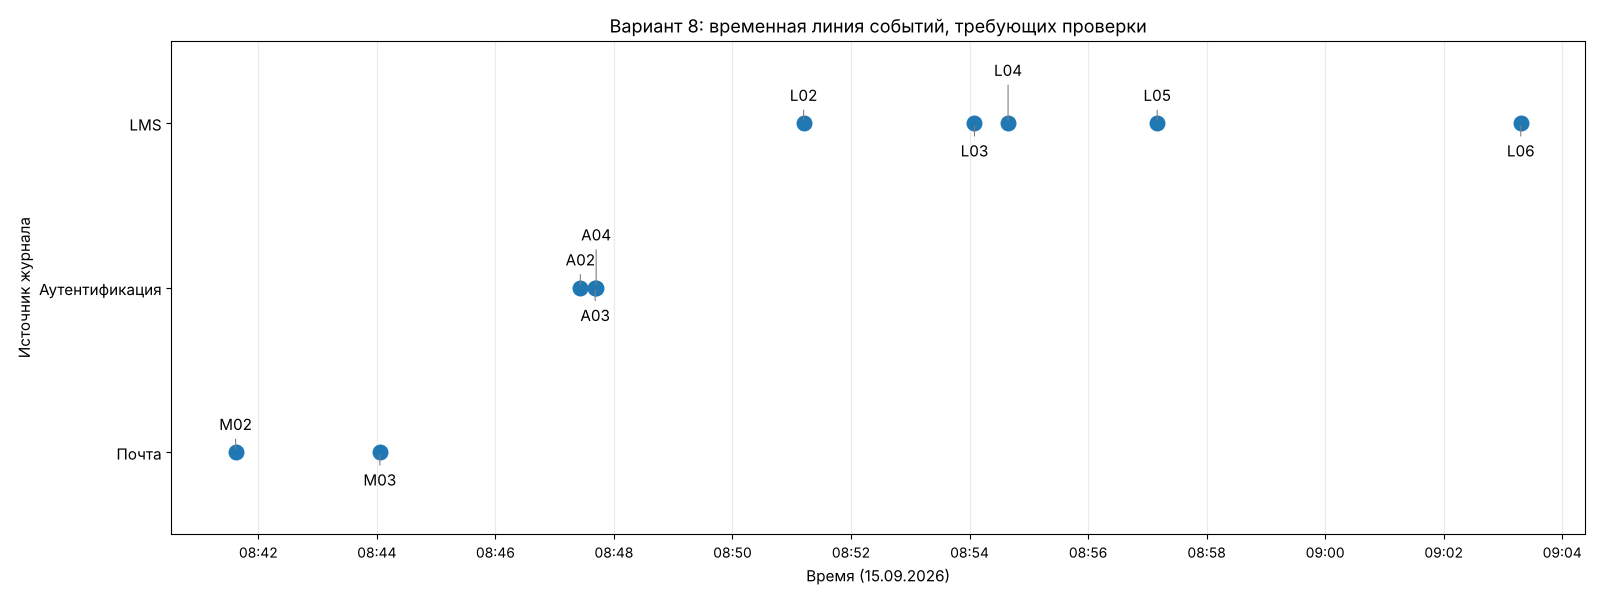

In [ ]:
if incident_df.empty:
    print('Для выбранного варианта автоматические признаки инцидента не обнаружены.')
else:
    import matplotlib.dates as mdates

    source_order = {'Почта': 0, 'Аутентификация': 1, 'LMS': 2}
    plot_df = incident_df.sort_values('datetime').copy()
    plot_df['source_y'] = plot_df['source'].map(source_order)

    plt.figure(figsize=(16, 6))
    plt.scatter(plot_df['datetime'], plot_df['source_y'], s=110, zorder=3)

    # Подписи чередуются по высоте, чтобы ID близких событий не накладывались друг на друга.
    offsets = [(0, 16), (0, -24), (0, 34)]
    counters = {}
    for _, row in plot_df.iterrows():
        k = counters.get(row['source'], 0)
        counters[row['source']] = k + 1
        dx, dy = offsets[k % len(offsets)]
        plt.annotate(row['event_id'], (row['datetime'], row['source_y']),
                     xytext=(dx, dy), textcoords='offset points', ha='center', fontsize=11,
                     arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))

    plt.yticks(list(source_order.values()), list(source_order.keys()), fontsize=11)
    plt.ylim(-0.5, 2.5)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    plt.gca().xaxis.set_major_locator(mdates.MinuteLocator(interval=2))
    plt.xlabel('Время (15.09.2026)', fontsize=11)
    plt.ylabel('Источник журнала', fontsize=11)
    plt.title(f'Вариант {VARIANT}: временная линия событий, требующих проверки', fontsize=13)
    plt.grid(True, axis='x', alpha=0.25)
    plt.tight_layout()
    plt.show()


## 5. График 2 — где сосредоточены события

Столбчатая диаграмма показывает, из каких журналов пришли события, вошедшие в контур инцидента. Она полезна при объяснении, почему для расследования недостаточно смотреть только один журнал.

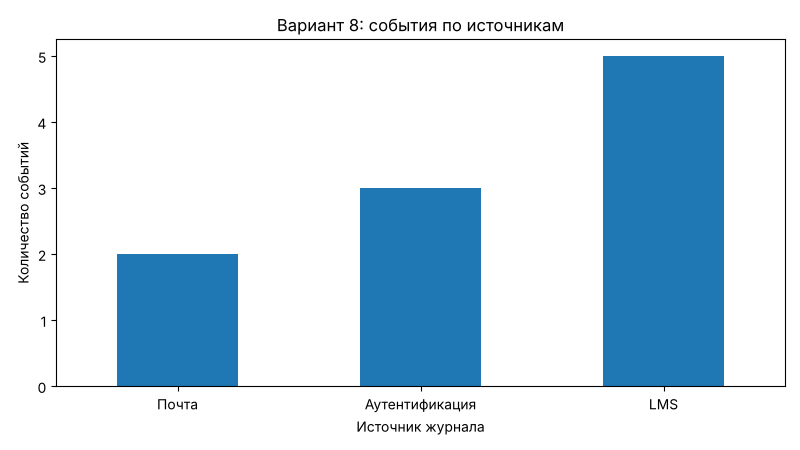

                Количество
source                    
Почта                    2
Аутентификация           3
LMS                      5

In [ ]:
if incident_df.empty:
    print('Нет данных для диаграммы.')
else:
    counts = (incident_df['source']
              .value_counts()
              .reindex(['Почта','Аутентификация','LMS'])
              .fillna(0)
              .astype(int))

    plt.figure(figsize=(8, 4.5))
    counts.plot(kind='bar')
    plt.xlabel('Источник журнала')
    plt.ylabel('Количество событий')
    plt.title(f'Вариант {VARIANT}: события по источникам')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    display(counts.rename('Количество').to_frame())

## 6. Короткая автоматическая сводка

Эта сводка помогает начать письменный анализ. Её **не следует вставлять в отчёт без собственного объяснения**: студент должен сослаться на ID событий, отделить факты от гипотез и ответить на вопросы своего варианта.

In [ ]:
if incident_df.empty:
    display(Markdown('**Вывод:** автоматические признаки не выявлены; требуется ручная проверка событий варианта.'))
else:
    first_time = incident_df['datetime'].min().strftime('%H:%M:%S')
    last_time = incident_df['datetime'].max().strftime('%H:%M:%S')
    ids = ', '.join(incident_df.sort_values('datetime')['event_id'].tolist())
    external_ips = sorted(set(ip for ip in incident_df['ip'].dropna().astype(str) if is_external_ip(ip)))
    ip_text = ', '.join(external_ips) if external_ips else 'не выявлены'

    summary = f"""**Автоматическая сводка по варианту {VARIANT}:**

- событий, требующих проверки: **{len(incident_df)}**;
- интервал зафиксированных событий: **{first_time}–{last_time}**;
- ID событий: **{ids}**;
- внешние IP в выборке: **{ip_text}**.

Сводка показывает только наблюдаемые признаки. Причину инцидента и виновное лицо по этим данным автоматически устанавливать нельзя."""
    display(Markdown(summary))

**Автоматическая сводка по варианту 8:**

- событий, требующих проверки: **10**;
- интервал зафиксированных событий: **08:41:37–09:03:18**;
- ID событий: **M02, M03, A02, A03, A04, L02, L03, L04, L05, L06**;
- внешние IP в выборке: **203.0.113.77**.

Сводка показывает только наблюдаемые признаки. Причину инцидента и виновное лицо по этим данным автоматически устанавливать нельзя.

## 7. Экспорт своей выборки

При необходимости можно сохранить два файла: все события своего варианта и только события, требующие проверки. Эти CSV удобно использовать как приложение к отчёту или как основу для собственной таблицы.

In [ ]:
variant_export = f'pr_03_variant_{VARIANT:02d}_all_events.csv'
incident_export = f'pr_03_variant_{VARIANT:02d}_incident_events.csv'

variant_df.drop(columns=['datetime']).to_csv(variant_export, sep=';', index=False, encoding='utf-8-sig')
incident_df.drop(columns=['datetime'], errors='ignore').to_csv(incident_export, sep=';', index=False, encoding='utf-8-sig')

print('Сохранено:')
print(' -', variant_export)
print(' -', incident_export)

Сохранено:
 - pr_03_variant_08_all_events.csv
 - pr_03_variant_08_incident_events.csv
